# Figure S20: Cross-QTL posterior distributions

Recalculate density displays and strict posterior-threshold counts from saved gene, credible-set, and variant colocalization results.


## Run the notebook

Use the R kernel. Start in the repository root. Set `QTL_PAPER_ROOT` to the local
paper directory and `QTL_SOURCE_ROOT` to the figure checkout with staged inputs
and saved objects. For example, set these variables in the R session before
you run the cells. Paths can contain spaces.

Run the cells from top to bottom. The notebook reads the recorded figure data.
It does not rerun upstream QTL mapping unless a section explicitly says so.
New PDFs and PNGs go to `notebook_outputs/`. Inputs stay in place.
The source scripts are in `notebooks/current/`. Figures shown below are aggregate
plots. Do not print participant tables into a saved notebook.


## Scope

The unit differs between GLCP, RCP, and SCP: genes, credible-set pairings, and variants. Posterior probabilities are not P values.

Density estimation and threshold counting are repeated, but FastENLOC and fine-mapping are not rerun. Only aggregate counts are exported.

The saved source has 15 GLCP values above 1 (maximum 1.008) and 2 RCP values above 1 (maximum 1.002). The notebook retains them as the original code does and exports a bounds audit. Their cause requires upstream review.


## Setup

Validate the local input paths and load the plot libraries.


In [1]:
# Shared setup for the November 2 figure notebooks.
suppressPackageStartupMessages({
  library(tidyverse)
  library(patchwork)
})
if (requireNamespace("showtext", quietly = TRUE)) showtext::showtext_auto(FALSE)

paper_root <- Sys.getenv("QTL_PAPER_ROOT")
source_root <- Sys.getenv("QTL_SOURCE_ROOT", getwd())
notebook_output <- Sys.getenv("QTL_NOTEBOOK_OUTPUT", file.path(getwd(), "notebook_outputs"))
input_records <- new.env(parent = emptyenv())

checked_input <- function(root, relative, variable) {
  if (!nzchar(root)) stop("Set ", variable, " before you run this notebook.", call. = FALSE)
  if (grepl("^(gs|s3|https?)://", root)) {
    stop("Input localization error: ", variable, " must be a local directory.", call. = FALSE)
  }
  path <- file.path(root, relative)
  if (!file.exists(path) || file.access(path, 4) != 0) {
    stop("Missing or unreadable input: ", relative, ". Check ", variable, ".", call. = FALSE)
  }
  path <- normalizePath(path, mustWork = TRUE)
  input_records[[paste(variable, relative, sep = ":")]] <- list(
    root = variable, path = relative, md5 = unname(tools::md5sum(path)))
  path
}
paper_file <- function(relative) checked_input(paper_root, relative, "QTL_PAPER_ROOT")
source_file <- function(relative) checked_input(source_root, relative, "QTL_SOURCE_ROOT")
output_file <- function(relative) {
  path <- file.path(notebook_output, relative)
  dir.create(dirname(path), recursive = TRUE, showWarnings = FALSE)
  path
}

save_plot <- function(plot, name, width_mm = 180, height_mm = 130) {
  message("Export aggregate plot: ", name)
  for (extension in c("pdf", "png")) {
    ggplot2::ggsave(output_file(paste0(name, ".", extension)), plot,
                   width = width_mm, height = height_mm, units = "mm", dpi = 180,
                   device = if (extension == "pdf") grDevices::cairo_pdf else "png",
                   bg = "white", limitsize = FALSE)
  }
  invisible(plot)
}

display_image <- function(path) {
  capture <- getOption("qtl.notebook.display")
  if (is.function(capture)) capture(path) else IRdisplay::display_png(file = path)
  invisible(NULL)
}
show_reference <- function(number) {
  path <- paper_file(paste0("output/Science_submission_package_20261102/Figures/Figure", number, ".png"))
  message("Display the archived November 2 submission image for Figure ", number, ".")
  display_image(path)
}

theme_set(theme_classic(base_size = 9) +
            theme(plot.title = element_blank(), plot.subtitle = element_blank(),
                  legend.title = element_blank(), panel.grid = element_blank()))
options(repr.plot.width = 10, repr.plot.height = 7, repr.plot.res = 150)
message("Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.")


Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.


## Read the saved posterior results

Rebuild S20 from the saved FastENLOC gene, credible-set, and variant results. This notebook recalculates density displays and threshold counts from those results. It does not rerun colocalization or fine-mapping. GLCP, RCP, and SCP are posterior probabilities, not P values.


In [2]:
specs <- tibble(level = c("GLCP", "RCP", "SCP"),
                file = c("coloc_gene_level", "coloc_cs_level", "coloc_variant_level"))
posterior <- purrr::map2_dfr(specs$level, specs$file, function(level, file) {
  d <- readRDS(source_file(paste0("Fig3/data/", file, ".rds")))
  d %>% transmute(assay_pair = type, posterior = .data[[level]], level = level)
}) %>% mutate(level = factor(level, c("GLCP", "RCP", "SCP")))
stopifnot(all(is.finite(posterior$posterior)), all(posterior$posterior >= 0))
source_bounds <- posterior %>% group_by(level, assay_pair) %>%
  summarise(records = n(), above_one = sum(posterior > 1), maximum = max(posterior), .groups = "drop")


## Calculate the display summaries

Count records with posterior strictly greater than 0.01, 0.1, 0.5, and 0.9. The unit differs between levels: genes, credible-set pairings, or variants. The saved GLCP/RCP data include 17 values slightly above one, with maxima 1.008 and 1.002. Preserve these source values, as the original supplemental code does. Save a bounds audit rather than silently clipping them.


In [3]:
thresholds <- purrr::map_dfr(c(0.01, 0.1, 0.5, 0.9), function(cutoff) {
  posterior %>% group_by(level, assay_pair) %>%
    summarise(n_tested = n(), n_coloc = sum(posterior > cutoff, na.rm = TRUE), .groups = "drop") %>%
    mutate(threshold = cutoff)
})
density_plot <- ggplot(posterior, aes(posterior, fill = assay_pair)) +
  geom_density(alpha = 0.7, na.rm = TRUE) + facet_wrap(~level, nrow = 1, scales = "free_y") +
  labs(x = "Posterior probability", y = "Density", fill = "Assay pair") +
  theme_classic(base_size = 9) + theme(strip.background = element_blank(), legend.position = "bottom")
discovery_plot <- ggplot(thresholds, aes(threshold, n_coloc, colour = assay_pair)) +
  geom_point(size = 1.5) + geom_line() + facet_wrap(~level, nrow = 1) +
  scale_y_log10(labels = scales::label_comma()) +
  labs(x = "Posterior threshold", y = "Colocalization records (log scale)", colour = "Assay pair") +
  theme_classic(base_size = 9) + theme(strip.background = element_blank(), legend.position = "none")


## Display and save aggregate results

The two rows match the scope of the original supplemental QC code. Save only the figure and threshold summaries. No variant or participant rows are exported.


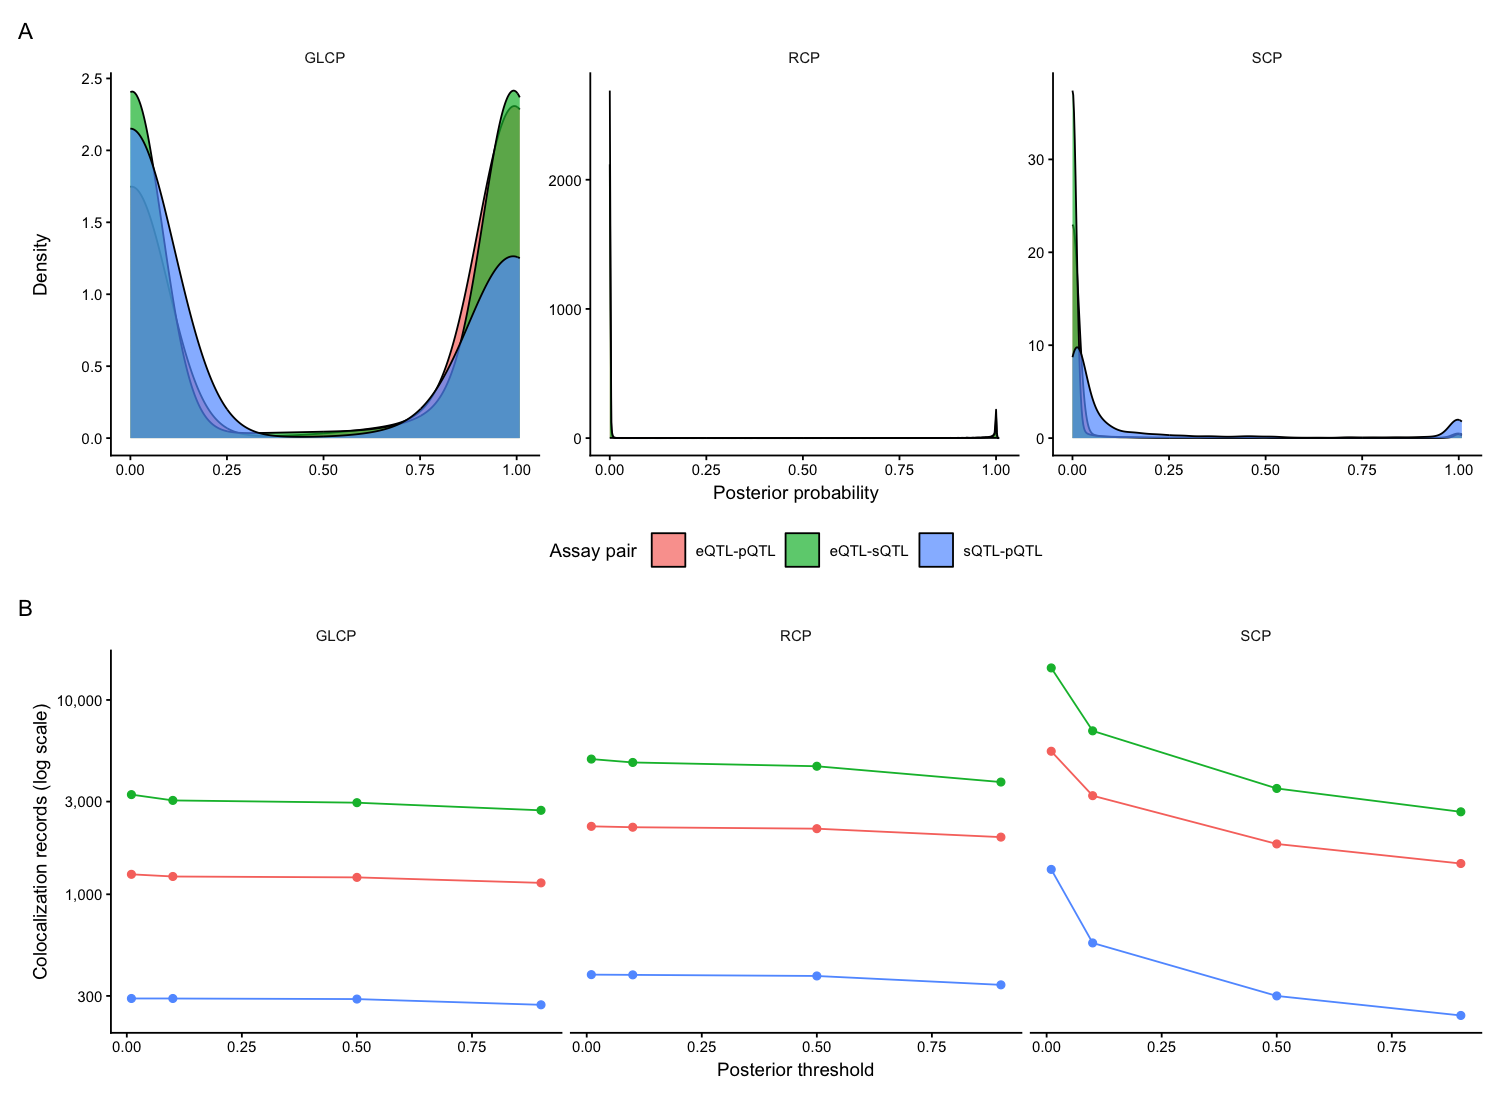

Export aggregate plot: supplements/S20


In [4]:
figure <- density_plot / discovery_plot + patchwork::plot_annotation(tag_levels = "A")
print(figure)
save_plot(figure, "supplements/S20", 184, 160)
readr::write_tsv(thresholds, output_file("supplements/S20_threshold_counts.tsv"))
readr::write_tsv(source_bounds, output_file("supplements/S20_source_bounds.tsv"))
